GROUND TRUTH - hourly
https://www.ncei.noaa.gov/access/search/data-search/global-historical-climatology-network-hourly?pageNum=1&pageSize=100&bbox=30.114,-90.095,29.988,-89.976&startDate=2024-03-30T00:00:00&endDate=2024-03-30T23:59:59

In [27]:
import pandas as pd

file_path = "GHCNh_USW00053917_2024.psv"
df = pd.read_csv(file_path, sep="|", dtype=str)

# Convert DATE to datetime
df['DATE'] = pd.to_datetime(df['DATE'])

# Approximate to the nearest o'clock
def round_hour(dt):
    rounded = dt.replace(second=0, microsecond=0)
    if dt.minute >= 30:
        rounded += pd.Timedelta(hours=1)
    return rounded.replace(minute=0)

df['RoundedHour'] = df['DATE'].apply(round_hour)

# Convert temp & precip to float for correct formatting
df['temperature'] = df['temperature'].astype(float)
df['precipitation'] = df['precipitation'].astype(float)

# Filter (optional, as per your example, precip >= 0)
filtered = df[df['precipitation'] >= 0]

# Build new DataFrame with required columns
out_df = filtered.loc[:, ['RoundedHour', 'temperature', 'precipitation']].copy()
out_df.columns = ['Time', 'Temperature', 'Precipitation']

# If you want to reset the index:
out_df = out_df.reset_index(drop=True)

print(out_df)

# Optionally, save to CSV
out_df.to_csv("Weather-Data.csv", index=False)

                    Time  Temperature  Precipitation
0    2024-01-01 01:00:00         13.9            0.0
1    2024-01-01 02:00:00         12.2            0.0
2    2024-01-01 03:00:00         11.7            0.0
3    2024-01-01 04:00:00         11.1            0.0
4    2024-01-01 05:00:00         11.1            0.0
...                  ...          ...            ...
8729 2024-12-31 20:00:00         20.0            0.0
8730 2024-12-31 21:00:00         20.0            0.0
8731 2024-12-31 22:00:00         20.6            0.0
8732 2024-12-31 23:00:00         19.4            0.0
8733 2025-01-01 00:00:00         17.8            0.0

[8734 rows x 3 columns]


In [14]:
import h5py

file_path = "2A.GPM.GMI.GPROF2021v1.20250111-S013100-E030413.061720.V07C.HDF5"

with h5py.File(file_path, "r") as hdf_file:
    columns = []
    hdf_file.visit(columns.append)
    print(columns)

['GprofDHeadr', 'GprofDHeadr/clusterProfiles', 'GprofDHeadr/hgtTopLayer', 'GprofDHeadr/speciesDescription', 'GprofDHeadr/temperatureDescriptions', 'S1', 'S1/L1CqualityFlag', 'S1/Latitude', 'S1/Longitude', 'S1/SCstatus', 'S1/SCstatus/FractionalGranuleNumber', 'S1/SCstatus/SCaltitude', 'S1/SCstatus/SClatitude', 'S1/SCstatus/SClongitude', 'S1/SCstatus/SCorientation', 'S1/ScanTime', 'S1/ScanTime/DayOfMonth', 'S1/ScanTime/DayOfYear', 'S1/ScanTime/Hour', 'S1/ScanTime/MilliSecond', 'S1/ScanTime/Minute', 'S1/ScanTime/Month', 'S1/ScanTime/Second', 'S1/ScanTime/SecondOfDay', 'S1/ScanTime/Year', 'S1/airmassLiftIndex', 'S1/cloudWaterPath', 'S1/convectivePrecipitation', 'S1/frozenPrecipitation', 'S1/iceWaterPath', 'S1/mostLikelyPrecipitation', 'S1/pixelStatus', 'S1/precip1stTertial', 'S1/precip2ndTertial', 'S1/precipitationYesNoFlag', 'S1/probabilityOfPrecip', 'S1/profileNumber', 'S1/profileScale', 'S1/profileTemp2mIndex', 'S1/qualityFlag', 'S1/rainWaterPath', 'S1/sunGlintAngle', 'S1/sunLocalTime',

In [58]:
scan_i = 1500
pix_j = 101
with h5py.File(file_path, "r") as hdf:
    tcwv_index = hdf["S1/totalColumnWaterVaporIndex"][scan_i, pix_j]
    lat = hdf["S1/Latitude"][scan_i, pix_j]
    lon = hdf["S1/Longitude"][scan_i, pix_j]
    year = hdf["S1/ScanTime/Year"][scan_i]
    month = hdf["S1/ScanTime/Month"][scan_i]
    day = hdf["S1/ScanTime/DayOfMonth"][scan_i]
    hour = hdf["S1/ScanTime/Hour"][scan_i]
    minute = hdf["S1/ScanTime/Minute"][scan_i]
    second = hdf["S1/ScanTime/Second"][scan_i]
print(tcwv_index, lat, lon, f"{year}-{month:02}-{day:02} {hour:02}:{minute:02}:{second:02}Z")

6 65.35765 -167.3902 2025-01-11 02:17:53Z


GMI GPM - 16 files / day (1.5h) - see scantime fields

https://disc.gsfc.nasa.gov/datasets/GPM_2AGPROFGPMGMI_07/summary?keywords=rainfall

In [25]:
import h5py
import numpy as np
import pandas as pd
import glob
import os

def extract_gprof_pixel_to_df(file_path, i, j, dataset_names, coords=False):
    with h5py.File(file_path, "r") as f:
        lat = f["S1_Latitude"][:]
        lon = f["S1_Longitude"][:]

        if coords is True:
            dist2 = (lat - i)**2 + (lon - j)**2
            i, j = np.unravel_index(np.argmin(dist2), lat.shape)

        def get_value(name):
            try:
                dset = f[name]
            except KeyError:
                parts = name.split('/')
                grp, key = '/'.join(parts[:-1]), parts[-1]
                dset = f[grp][key]
            if dset.shape == lat.shape:
                return dset[i, j]
            elif (len(dset.shape) == 1) and (dset.shape[0] == lat.shape[0]):
                return dset[i]
            elif (len(dset.shape) == 3) and (dset.shape[1:] == lat.shape):
                return dset[0, i, j]
            else:
                try:
                    return dset[()]
                except Exception:
                    return None

        pixel_data = {}
        for name in dataset_names:
            if name.endswith('/'): continue
            pixel_data[name] = get_value(name)

        # pixel_data['pixel_index'] = (int(i), int(j))
        # pixel_data['actual_lat'] = float(lat[i, j])
        # pixel_data['actual_lon'] = float(lon[i, j])

        # Combine and format datetime (rounding minute to nearest hour)
        year   = int(pixel_data.get("S1_ScanTime_Year", 0))
        month  = int(pixel_data.get("S1_ScanTime_Month", 0))
        day    = int(pixel_data.get("S1_ScanTime_DayOfMonth", 0))
        hour   = int(pixel_data.get("S1_ScanTime_Hour", 0))
        minute = int(pixel_data.get("S1_ScanTime_Minute", 0))
        if minute >= 30:
            hour = (hour + 1) % 24
        pixel_data['Time'] = f"{year:04d}-{month:02d}-{day:02d} {hour:02d}:00"

        # Remove individual time fields
        for col in [
            "S1_ScanTime_Year", "S1_ScanTime_Month", 
            "S1_ScanTime_DayOfMonth", "S1_ScanTime_Hour", "S1_ScanTime_Minute", "S1_ScanTime_DayOfYear"
        ]:
            pixel_data.pop(col, None)

        return pixel_data  # Note: return as dict for batch easier

# Example usage for all files in a folder
folder = "GPM-GMI"
i, j = 30.047567, -90.06331
dataset_names = [
    'nscan', 'npixel', 'S1_ScanTime_Minute', 'S1_ScanTime_Year', 'S1_ScanTime_DayOfYear', 'S1_ScanTime_Hour', 'S1_ScanTime_Month', 'S1_ScanTime_DayOfMonth', 'S1_SCstatus_SCaltitude', 'S1_iceWaterPath', 'S1_surfacePrecipitation', 'S1_frozenPrecipitation', 'S1_cloudWaterPath', 'S1_totalColumnWaterVaporIndex', 'S1_probabilityOfPrecip', 'S1_mostLikelyPrecipitation', 'S1_surfaceTypeIndex', 'S1_rainWaterPath', 'S1_convectivePrecipitation', 'S1_airmassLiftIndex',
]

rows = []
for file_path in glob.glob(os.path.join(folder, "*.HDF5.nc4")):
    try:
        row = extract_gprof_pixel_to_df(file_path, i, j, dataset_names, coords=True)
        rows.append(row)
    except Exception as e:
        print(f"Error in file {file_path}: {e}")

df = pd.DataFrame(rows)
print(df)
df.to_csv("GPM-GMI.csv", index=False)

      nscan                                             npixel  \
0       0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1       0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
2       0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
3       0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
4       0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
...     ...                                                ...   
1238    0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1239    0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1240    0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1241    0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1242    0.0  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   

      S1_SCstatus_SCaltitude  S1_iceWaterPath  S1_surfacePrecipitation  \
0                 438.860504         0.024721                 0.006564   
1                 441.667053         0.023530              

In [6]:
import h5py
import numpy as np

file_path = "2A.GPM.GMI.GPROF2021v1.20250111-S013100-E030413.061720.V07C.HDF5"

with h5py.File(file_path, "r") as hdf:
    lat = hdf["S1/Latitude"][:]
    lon = hdf["S1/Longitude"][:]

# Flatten
lat_f = lat.ravel()
lon_f = lon.ravel()

# Optional masking: remove out-of-range or fill values if any (example thresholds)
mask = (lat_f >= -90) & (lat_f <= 90) & (lon_f >= -180) & (lon_f <= 180)
lat_f = lat_f[mask]
lon_f = lon_f[mask]

print("Total points:", lat_f.size)

Total points: 659464


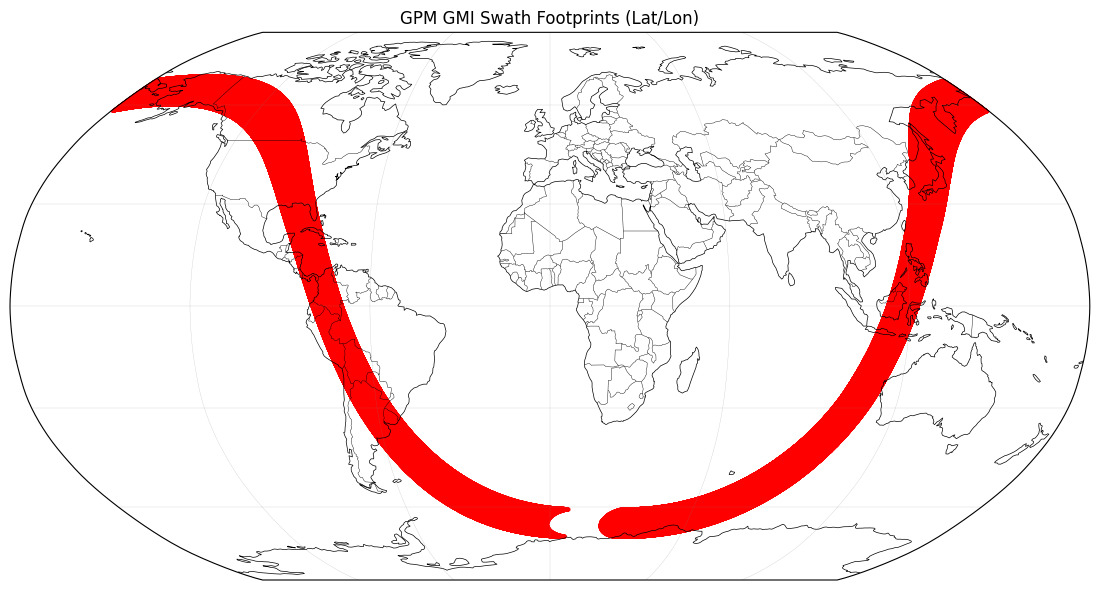

In [14]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Robinson())  # or PlateCarree()
ax.set_global()
ax.coastlines(linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linewidth=0.3)
ax.gridlines(draw_labels=False, linewidth=0.2, color='gray', alpha=0.5)

# Use PlateCarree for data transform
ax.scatter(lon_f, lat_f, s=10, c="red", alpha=0.7, transform=ccrs.PlateCarree(), linewidth=0)

plt.title("GPM GMI Swath Footprints (Lat/Lon)")
plt.tight_layout()
plt.show()

In [23]:
import numpy as np

def cel_mai_apropiat_punct(lat_f, lon_f, input_lat, input_lon):
    """
    Returnează indicele și coordonatele punctului cel mai apropiat de (input_lat, input_lon)
    din array-urile lat_f și lon_f.
    """
    # Transformă coordonatele în array NumPy, dacă nu sunt deja
    lat_f = np.asarray(lat_f)
    lon_f = np.asarray(lon_f)

    # Distanta euclidiană aproximativă (poate fi adaptată cu Haversine pentru acuratețe pe glob)
    d2 = (lat_f - input_lat)**2 + (lon_f - input_lon)**2
    idx_min = np.argmin(d2)
    return idx_min, lat_f[idx_min], lon_f[idx_min]

input_lat, input_lon = 30.049512354896585, -90.02919649752155

idx, lat_cel_mai_apropiat, lon_cel_mai_apropiat = cel_mai_apropiat_punct(lat_f, lon_f, input_lat, input_lon)
print("Cel mai apropiat punct are coordonatele:", lat_cel_mai_apropiat, lon_cel_mai_apropiat)

Cel mai apropiat punct are coordonatele: 30.047567 -90.06331


In [16]:
from netCDF4 import Dataset

# file_path = "MERRA2_400.tavg1_2d_flx_Nx.20240831.nc4"
file_path = "MERRA2_400.tavg1_2d_flx_Nx.20240101.SUB.nc"
with Dataset(file_path) as ds:
    print("Dimensions:")
    for dim in ds.dimensions.values():
        print(f"  {dim.name}: size={len(dim)}")

    print("\nVariables:")
    for var in ds.variables.values():
        print(f"  {var.name}: shape={var.shape}, dtype={var.dtype}")

    print("\nGlobal Attributes:")
    for attr in ds.ncattrs():
        print(f"  {attr}: {getattr(ds, attr)}")

Dimensions:
  time: size=24
  lon: size=3
  lat: size=4

Variables:
  time: shape=(24,), dtype=int32
  lon: shape=(3,), dtype=float64
  lat: shape=(4,), dtype=float64
  EFLUX: shape=(24, 4, 3), dtype=float32
  EVAP: shape=(24, 4, 3), dtype=float32
  FRCAN: shape=(24, 4, 3), dtype=float32
  FRCCN: shape=(24, 4, 3), dtype=float32
  FRCLS: shape=(24, 4, 3), dtype=float32
  HFLUX: shape=(24, 4, 3), dtype=float32
  HLML: shape=(24, 4, 3), dtype=float32
  PBLH: shape=(24, 4, 3), dtype=float32
  PRECANV: shape=(24, 4, 3), dtype=float32
  PRECCON: shape=(24, 4, 3), dtype=float32
  PRECLSC: shape=(24, 4, 3), dtype=float32
  PRECTOT: shape=(24, 4, 3), dtype=float32
  QLML: shape=(24, 4, 3), dtype=float32
  RISFC: shape=(24, 4, 3), dtype=float32
  TLML: shape=(24, 4, 3), dtype=float32
  ULML: shape=(24, 4, 3), dtype=float32
  USTAR: shape=(24, 4, 3), dtype=float32
  VLML: shape=(24, 4, 3), dtype=float32

Global Attributes:
  CDI: Climate Data Interface version 1.9.8 (https://mpimet.mpg.de/cdi)
  

IR (frames of 30 min)

https://disc.gsfc.nasa.gov/datasets/GPM_MERGIR_1/summary?keywords=rainfall

In [9]:
import os
from netCDF4 import Dataset, num2date
import numpy as np
import pandas as pd

data_folder = 'IR'
target_lat = 30.047567
target_lon = -90.06331

df_list = []

for file in sorted(os.listdir(data_folder)):
    if not file.endswith(".nc4"):
        continue
    file_path = os.path.join(data_folder, file)
    with Dataset(file_path) as ds:
        lats = ds.variables['lat'][:]
        lons = ds.variables['lon'][:]
        tb = ds.variables['Tb'][:]  # shape: (time, lat, lon)
        time_var = ds.variables['time']
        time = time_var[:]
        # Convert time to datetime objects
        time_units = time_var.units
        try:
            time_calendar = time_var.calendar
        except AttributeError:
            time_calendar = "standard"  # default
    
        time_vals = num2date(time, units=time_units, calendar=time_calendar)

        # Find closest gridpoint for (target_lat, target_lon)
        ilat = np.abs(lats - target_lat).argmin()
        ilon = np.abs(lons - target_lon).argmin()
        tb_timeseries = tb[:, ilat, ilon]
        
        # print(lats[ilat], lons[ilon])
        
        # Append to list
        hour_str = time_vals[0].strftime('%Y-%m-%d %H:00')
        df_list.append({'Time': hour_str, 'Tb': tb_timeseries[0]})

# Combine to DataFrame
df = pd.DataFrame(df_list)
print(df)

                  Time   Tb
0     2023-12-31 00:00  284
1     2023-12-31 01:00  283
2     2023-12-31 02:00  283
3     2023-12-31 03:00  283
4     2023-12-31 04:00  283
...                ...  ...
8803  2024-12-31 19:00  290
8804  2024-12-31 20:00  290
8805  2024-12-31 21:00  290
8806  2024-12-31 22:00  290
8807  2024-12-31 23:00  289

[8808 rows x 2 columns]


In [12]:
def is_masked(x):
    return getattr(x, 'mask', False)

# First, ensure all non-masked values are numeric (convert if necessary)
df['Tb'] = df['Tb'].apply(lambda x: np.nan if is_masked(x) else x)
df['Tb'] = pd.to_numeric(df['Tb'], errors='coerce')

# Find indices where the original values are masked (now np.nan)
masked_idx = df['Tb'][df['Tb'].isna()].index

# Fill each masked value with the mean of the previous and next value, rounded
for idx in masked_idx:
    prev_val = df['Tb'][idx-1] if idx > 0 else np.nan
    next_val = df['Tb'][idx+1] if idx < len(df['Tb'])-1 else np.nan
    vals = [v for v in [prev_val, next_val] if not pd.isna(v)]
    if vals:
        df.at[idx, 'Tb'] = int(round(np.mean(vals)))
    else:
        df.at[idx, 'Tb'] = np.nan  # Both neighbors are NaN, leave as NaN

In [13]:
print(df['Tb'][308])
masked_count = df['Tb'].apply(lambda x: getattr(x, 'mask', False)).sum()

print(f"Number of masked values in Tb: {masked_count}")

278.0
Number of masked values in Tb: 0


In [15]:
import pandas as pd

# Suppose your DataFrame is named df
df.to_csv('IR.csv', index=False)

MERRA-2 (each hour)

In [8]:
import numpy as np
import netCDF4
from netCDF4 import Dataset
import pandas as pd
import glob
import os
import re

# Input: your location
input_lat, input_lon = 30.049512354896585, -90.02919649752155

# Variables to extract
var_names = [
    "EFLUX", "EVAP", "FRCAN", "FRCCN", "FRCLS", "HFLUX", "HLML", "PBLH",
    "PRECANV", "PRECCON", "PRECLSC", "PRECTOT", "QLML", "RISFC",
    "TLML", "ULML", "USTAR", "VLML"
]

folder = "MERRA-2"
all_rows = []

for file_path in glob.glob(os.path.join(folder, "*.nc")):
    m = re.search(r"(\d{8})", os.path.basename(file_path))
    file_type = m.group(1) if m else "unknown"
    date_str = f"{file_type[:4]}-{file_type[4:6]}-{file_type[6:8]}" if file_type != "unknown" else "0000-00-00"

    with Dataset(file_path) as ds:
        lats = ds.variables["lat"][:]
        lons = ds.variables["lon"][:]
        idx_lat = np.abs(lats - input_lat).argmin()
        idx_lon = np.abs(lons - input_lon).argmin()
        n_time = ds.variables["time"].shape[0]

        for t in range(n_time):
            # Compose time string
            time_str = f"{date_str} {t:02d}:00"
            row = {
                "Time": time_str,
            }
            for v in var_names:
                row[v] = ds.variables[v][t, idx_lat, idx_lon]
            all_rows.append(row)

df = pd.DataFrame(all_rows)
print(df.head())
df.to_csv("MERRA-2.csv", index=False)

               Time      EFLUX           EVAP FRCAN FRCCN        FRCLS  \
0  2024-01-01 00:00  1.9167061  7.7837376e-07   0.0   0.0    0.6315918   
1  2024-01-01 01:00    2.14003   8.675179e-07   0.0   0.0  0.018096924   
2  2024-01-01 02:00  2.2572346  9.1714446e-07   0.0   0.0          0.0   
3  2024-01-01 03:00  2.3940792    9.71826e-07   0.0   0.0          0.0   
4  2024-01-01 04:00   2.377079   9.664773e-07   0.0   0.0          0.0   

        HFLUX       HLML       PBLH PRECANV PRECCON        PRECLSC  \
0   -5.483036   64.20775   826.2258     0.0     0.0   8.557563e-26   
1  -6.9620247  64.103584   414.8729     0.0     0.0  1.4948914e-27   
2   -8.566914   64.00714  63.738678     0.0     0.0            0.0   
3  -10.283592  63.913162  63.632977     0.0     0.0            0.0   
4   -11.33717  63.830017   68.58089     0.0     0.0            0.0   

         PRECTOT          QLML       RISFC       TLML        ULML  \
0   8.557563e-26    0.00636936   1.1608067     289.14  0.26913655